
# Revisão de Resultados — Walk-forward OOS

Notebook focado na **validação walk-forward** (script 05): parâmetros otimizados por janela,
testes out-of-sample concatenados e CBE.

**Pré-requisito:** `python scripts/05_run_walk_forward.py --config config.dev.yaml`

O apêndice no final mostra o backtest fixo (script 04) apenas para comparação rápida.


In [9]:

import sys
from pathlib import Path

project_root = Path().resolve().parent
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import load_config, get_project_root, resolve_cost_bps, resolve_strategies

%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['legend.fontsize'] = 11

# --- Config ativa (None = config.yaml na raiz do projeto) ---
CONFIG_PATH = 'config.dev.yaml'

config_file = (project_root / CONFIG_PATH) if CONFIG_PATH else None
cfg = load_config(config_file)
root = get_project_root()
data_cfg = cfg['data']
wf_cfg = cfg.get('walk_forward', {})

tables_dir = root / 'results' / 'tables'
backtests_dir = root / 'data' / 'backtests'

ACTIVE_STRATEGIES = resolve_strategies(cfg)
SCENARIO_FEE_BPS, SCENARIO_SLIPPAGE_BPS = resolve_cost_bps(cfg)
SCENARIO_LABEL = f'fee={SCENARIO_FEE_BPS:g}bps, slip={SCENARIO_SLIPPAGE_BPS:g}bps'

print('Projeto:', root)
print('Config:', CONFIG_PATH or 'config.yaml')
print('Período:', data_cfg['start_date'], '→', data_cfg['end_date'])
print('Ativos:', data_cfg['symbols'], '| Intervalos:', data_cfg['intervals'])
print('Estratégias:', ACTIVE_STRATEGIES)
print(
    'WF janelas:', wf_cfg.get('train_days'), '+', wf_cfg.get('validation_days'), '+',
    wf_cfg.get('test_days'), 'dias | step', wf_cfg.get('step_days'),
)
print('Custo WF:', SCENARIO_LABEL)


def filter_strategies(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty or 'strategy' not in df.columns:
        return df
    return df[df['strategy'].isin(ACTIVE_STRATEGIES)].copy()


def chain_oos_equity(
    df_eq: pd.DataFrame,
    strategy: str,
    seed: int | None = None,
) -> pd.Series:
    """Encadeia equity dos períodos de teste OOS."""
    sub = df_eq[df_eq['strategy'] == strategy].copy()
    if seed is not None and 'seed' in sub.columns:
        sub = sub[sub['seed'] == seed]
    elif strategy == 'random' and 'seed' in sub.columns and sub['seed'].notna().any():
        return pd.Series(dtype=float)
    if sub.empty:
        return pd.Series(dtype=float)

    sub['timestamp'] = pd.to_datetime(sub['timestamp'])
    scale = 1.0
    parts: list[pd.Series] = []

    for _, grp in sub.groupby('window_id', sort=True):
        grp = grp.sort_values('timestamp')
        eq = grp.set_index('timestamp')['equity'].astype(float)
        if eq.index.duplicated().any():
            eq = eq[~eq.index.duplicated(keep='first')]
        if eq.empty:
            continue
        chained = eq / eq.iloc[0] * scale
        scale = float(chained.iloc[-1])
        parts.append(chained)

    if not parts:
        return pd.Series(dtype=float)
    return pd.concat(parts).sort_index()


def random_oos_equity_band(
    df_eq: pd.DataFrame,
) -> tuple[pd.Series, pd.Series, pd.Series]:
    """Faixa p05/p50/p95 da equity OOS encadeada entre seeds do random."""
    sub = df_eq[df_eq['strategy'] == 'random']
    if sub.empty or 'seed' not in sub.columns or not sub['seed'].notna().any():
        empty = pd.Series(dtype=float)
        return empty, empty, empty

    curves: list[pd.Series] = []
    for seed in sorted(sub['seed'].dropna().unique()):
        eq = chain_oos_equity(df_eq, 'random', seed=int(seed))
        if not eq.empty:
            curves.append(eq)

    if not curves:
        empty = pd.Series(dtype=float)
        return empty, empty, empty

    panel = pd.concat(curves, axis=1).sort_index().ffill()
    return panel.quantile(0.05, axis=1), panel.quantile(0.50, axis=1), panel.quantile(0.95, axis=1)


Projeto: C:\Users\Paulo\Documents\Pessoal\repositorios\researches_scripts\01-intraday-technical-indicator\intraday_regression_bands
Config: config.dev.yaml
Período: 2023-01-01 → 2023-03-31
Ativos: ['BTCUSDT'] | Intervalos: ['15m']
Estratégias: ['bollinger', 'regression_bands', 'return_residuals', 'random']
WF janelas: 21 + 7 + 1 dias | step 1
Custo WF: fee=0bps, slip=0bps



## 1. Carregar artefatos do walk-forward


In [10]:

wf_path = tables_dir / 'walk_forward_results.csv'
wf_oos_path = tables_dir / 'walk_forward_oos_summary.csv'
wf_seed_dist_path = tables_dir / 'walk_forward_random_seed_distribution.csv'
params_path = tables_dir / 'best_parameters_by_window.csv'
wf_equity_path = backtests_dir / 'walk_forward_equity.parquet'

df_wf = pd.read_csv(wf_path) if wf_path.exists() else pd.DataFrame()
df_wf_oos = pd.read_csv(wf_oos_path) if wf_oos_path.exists() else pd.DataFrame()
df_wf_seed_dist = pd.read_csv(wf_seed_dist_path) if wf_seed_dist_path.exists() else pd.DataFrame()
df_params = pd.read_csv(params_path) if params_path.exists() else pd.DataFrame()
df_wf_eq = pd.read_parquet(wf_equity_path) if wf_equity_path.exists() else pd.DataFrame()

df_wf = filter_strategies(df_wf)
df_wf_oos = filter_strategies(df_wf_oos)
df_params = filter_strategies(df_params)

if df_wf.empty:
    print('Execute: python scripts/05_run_walk_forward.py --config', CONFIG_PATH or 'config.yaml')
else:
    n_windows = df_wf['window_id'].nunique() if 'window_id' in df_wf.columns else len(df_wf)
    loaded = sorted(df_wf['strategy'].unique()) if 'strategy' in df_wf.columns else []
    missing = sorted(set(ACTIVE_STRATEGIES) - set(loaded))
    print(f'Janelas de teste OOS: {n_windows}')
    print(f'Linhas (janela × estratégia): {len(df_wf)}')
    print(f'Estratégias nos artefatos: {loaded}')
    if missing:
        print(f'AVISO: faltam no CSV — {missing}')
        print('  Rode o script 05 SEM --strategies (ou com todas) para gerar os resultados completos.')
        print('  Execuções parciais (--strategies random) sobrescreviam tudo antes; agora fazem merge.')
    print(f'Custo aplicado no WF: {SCENARIO_LABEL}')
    if not df_wf_oos.empty:
        print('Resumo OOS disponível:', wf_oos_path.name)
    if not df_wf_seed_dist.empty:
        print('Distribuição random:', wf_seed_dist_path.name)


Janelas de teste OOS: 61
Linhas (janela × estratégia): 6262
Estratégias nos artefatos: ['bollinger', 'random', 'regression_bands', 'return_residuals']
Custo aplicado no WF: fee=0bps, slip=0bps



## 2. Resumo OOS agregado (principal)

Métricas sobre **todos os períodos de teste concatenados**, com parâmetros otimizados janela a janela.
Fonte: `walk_forward_oos_summary.csv`.


In [11]:

if df_wf_oos.empty:
    print('Arquivo walk_forward_oos_summary.csv ausente. Reexecute o script 05.')
else:
    summary_cols = [
        'strategy', 'symbol', 'interval', 'n_windows',
        'oos_total_return', 'oos_sharpe', 'oos_max_drawdown',
        'break_even_total_return_bps', 'number_of_trades',
    ]
    oos = df_wf_oos[summary_cols].sort_values('oos_sharpe', ascending=False)
    pd.set_option('display.float_format', '{:.4f}'.format)
    display(oos.style.background_gradient(subset=['oos_sharpe'], cmap='RdYlGn'))


Arquivo walk_forward_oos_summary.csv ausente. Reexecute o script 05.



## 3. Sharpe por janela de teste

Cada ponto é **uma janela OOS** (parâmetros escolhidos só com treino+validação).


C:\Users\Paulo\AppData\Local\Temp\ipykernel_18272\2973657162.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(data, vert=True)


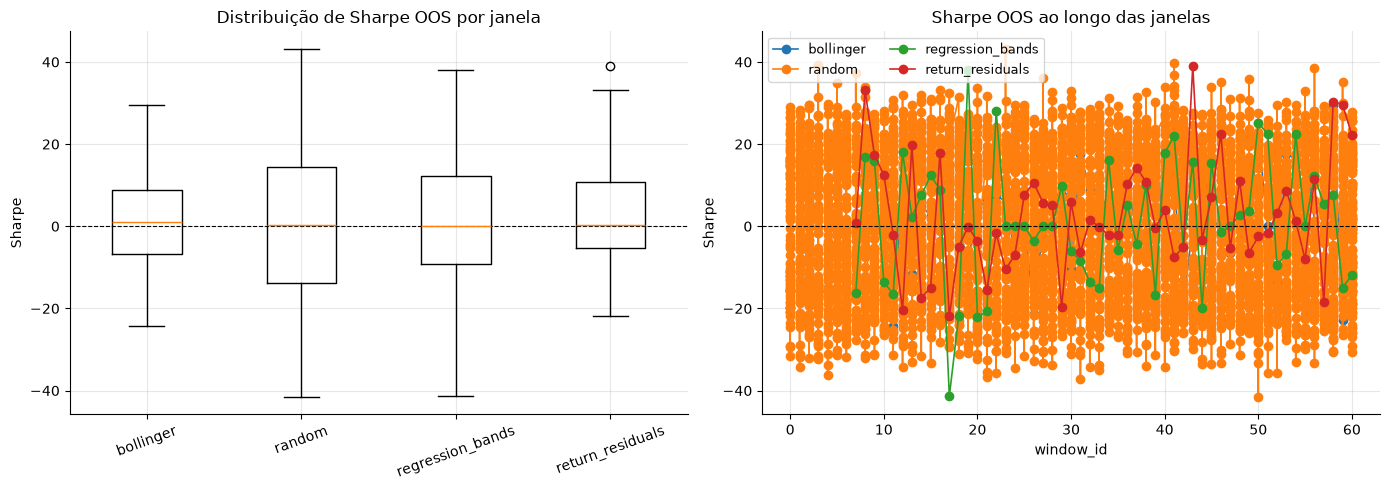

Estatísticas por estratégia (média e desvio entre janelas):


sharpe         annualized_return        max_drawdown       
                   mean     std              mean    std         mean    std
strategy                                                                    
bollinger        1.5989 12.1456           -0.3694 3.6390      -0.0132 0.0153
random           0.1337 15.9145            0.0141 1.5760      -0.0037 0.0042
regression_bands 1.2318 15.4072           -0.4246 4.7512      -0.0146 0.0163
return_residuals 2.8584 13.8229            0.7313 4.3552      -0.0155 0.0100

In [12]:

if df_wf.empty:
    print('Sem dados walk-forward.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    strategies = sorted(df_wf['strategy'].unique())
    data = [df_wf.loc[df_wf['strategy'] == s, 'sharpe'].dropna().values for s in strategies]
    axes[0].boxplot(data, vert=True)
    axes[0].set_xticks(range(1, len(strategies) + 1))
    axes[0].set_xticklabels(strategies, rotation=20)
    axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[0].set_title('Distribuição de Sharpe OOS por janela')
    axes[0].set_ylabel('Sharpe')

    for strat in strategies:
        sub = df_wf[df_wf['strategy'] == strat].sort_values('window_id')
        axes[1].plot(sub['window_id'], sub['sharpe'], marker='o', label=strat, linewidth=1.2)
    axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[1].set_xlabel('window_id')
    axes[1].set_ylabel('Sharpe')
    axes[1].set_title('Sharpe OOS ao longo das janelas')
    axes[1].legend(ncol=2, fontsize=9)

    for ax in axes:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    fig.tight_layout()
    plt.show()

    wf_by_window = (
        df_wf.groupby('strategy')[['sharpe', 'annualized_return', 'max_drawdown']]
        .agg(['mean', 'std'])
        .round(4)
    )
    print('Estatísticas por estratégia (média e desvio entre janelas):')
    display(wf_by_window)



## 4. Curvas de equity OOS encadeadas

Patrimônio simulado **somente nos períodos de teste**, encadeando janela a janela.
Não é o backtest fixo do script 04. Fonte: `walk_forward_equity.parquet`.


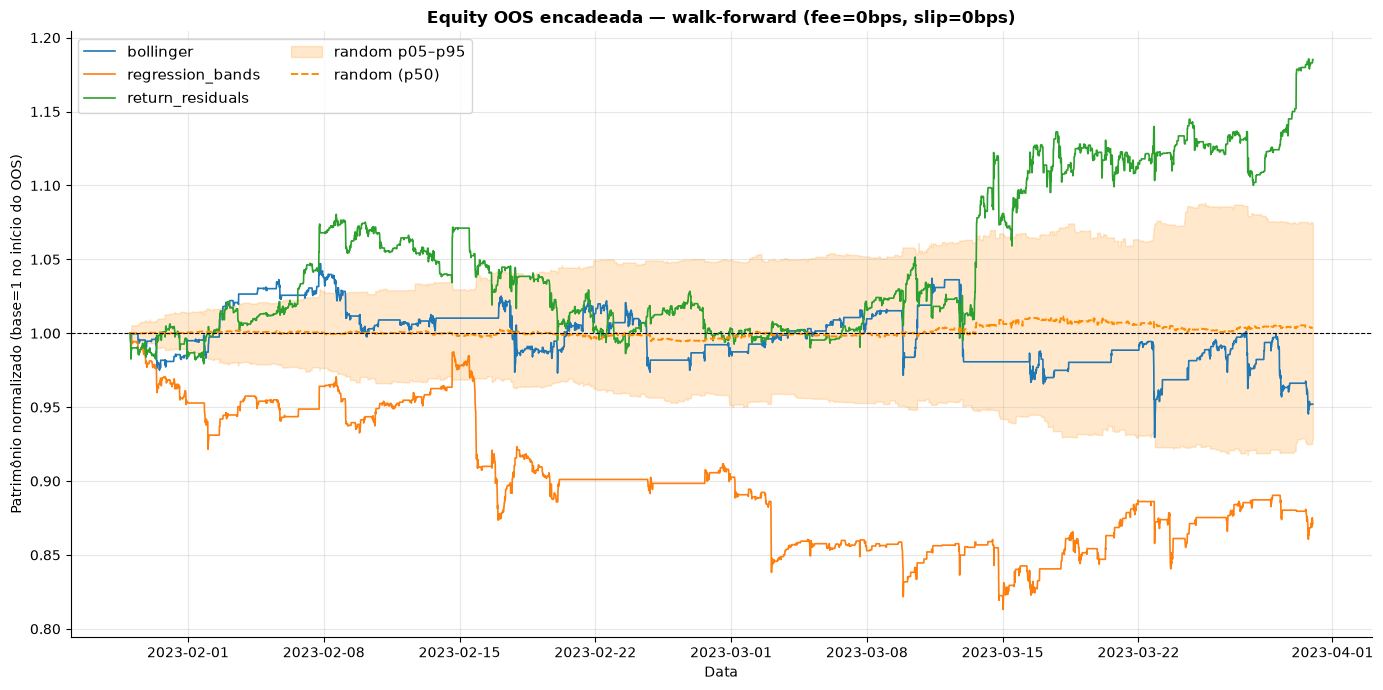

In [13]:

if df_wf_eq.empty:
    print('walk_forward_equity.parquet ausente. Reexecute o script 05.')
else:
    df_wf_eq = filter_strategies(df_wf_eq)
    fig, ax = plt.subplots(figsize=(14, 7))
    colors = plt.cm.tab10.colors
    color_idx = 0

    for strat in sorted(s for s in df_wf_eq['strategy'].unique() if s != 'random'):
        eq = chain_oos_equity(df_wf_eq, strat)
        if eq.empty:
            continue
        ax.plot(
            eq.index, eq.values,
            label=strat,
            color=colors[color_idx % len(colors)],
            linewidth=1.2,
        )
        color_idx += 1

    if 'random' in df_wf_eq['strategy'].values:
        p05, p50, p95 = random_oos_equity_band(df_wf_eq)
        if not p50.empty:
            ax.fill_between(
                p50.index, p05.values, p95.values,
                color='darkorange', alpha=0.20, label='random p05–p95',
            )
            ax.plot(
                p50.index, p50.values,
                color='darkorange', linewidth=1.4, linestyle='--',
                label='random (p50)',
            )

    ax.axhline(1.0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'Equity OOS encadeada — walk-forward ({SCENARIO_LABEL})', fontweight='bold')
    ax.set_ylabel('Patrimônio normalizado (base=1 no início do OOS)')
    ax.set_xlabel('Data')
    ax.legend(ncol=2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    fig.tight_layout()
    plt.show()



## 5. Parâmetros escolhidos por janela

Últimas janelas com os hiperparâmetros vencedores em treino+validação.


In [14]:

if df_params.empty:
    print('best_parameters_by_window.csv ausente.')
else:
    param_cols = [c for c in df_params.columns if c.startswith('param_')]
    show_cols = ['window_id', 'strategy', 'symbol', 'interval', 'val_metric'] + param_cols
    latest = (
        df_params[show_cols]
        .sort_values(['strategy', 'window_id'])
        .groupby('strategy', as_index=False)
        .tail(5)
    )
    display(latest)


,window_id,strategy,symbol,interval,val_metric,param_seed,param_trade_prob,param_window,param_k,param_entry_long_z,param_entry_short_z,param_exit_long_z,param_exit_short_z
49,56,bollinger,BTCUSDT,15m,11.5833,NaN,NaN,20.0000,1.5000,0.9000,0.8000,0.0000,0.0000
50,57,bollinger,BTCUSDT,15m,15.4574,NaN,NaN,20.0000,1.5000,0.9000,0.9000,0.0000,0.0000
51,58,bollinger,BTCUSDT,15m,15.6920,NaN,NaN,20.0000,2.5000,0.9000,0.8000,0.0000,0.0000
52,59,bollinger,BTCUSDT,15m,14.6124,NaN,NaN,20.0000,2.5000,0.9000,0.8000,0.0000,0.0000
53,60,bollinger,BTCUSDT,15m,9.5335,NaN,NaN,15.0000,4.0000,0.8000,0.9000,0.0000,0.0000
6017,60,random,BTCUSDT,15m,NaN,14149.0000,0.0500,NaN,NaN,NaN,NaN,NaN,NaN
6078,60,random,BTCUSDT,15m,NaN,14150.0000,0.0500,NaN,NaN,NaN,NaN,NaN,NaN
6139,60,random,BTCUSDT,15m,NaN,14151.0000,0.0500,NaN,NaN,NaN,NaN,NaN,NaN
6200,60,random,BTCUSDT,15m,NaN,14152.0000,0.0500,NaN,NaN,NaN,NaN,NaN,NaN
6261,60,random,BTCUSDT,15m,NaN,14153.0000,0.0500,NaN,NaN,NaN,NaN,NaN,NaN



## 6. Break-even (CBE) OOS

Quanto de **fee + slippage por lado** a estratégia validada aguenta antes de zerar o retorno OOS agregado.
`break_even_total_return_bps = 0` quando o OOS já perde sem custo.


In [15]:

if df_wf_oos.empty:
    print('walk_forward_oos_summary.csv ausente. Execute: python scripts/05_run_walk_forward.py')
else:
    bec_col = 'break_even_total_return_bps'
    real_oos = df_wf_oos[~df_wf_oos['strategy'].eq('random')].copy()
    random_oos = df_wf_oos[df_wf_oos['strategy'].eq('random')].copy()
    has_seed = 'seed' in random_oos.columns and random_oos['seed'].notna().any()

    active_cost = SCENARIO_FEE_BPS + SCENARIO_SLIPPAGE_BPS
    ref_lines = [
        (active_cost, 'blue', f'Cenário WF ({SCENARIO_LABEL})'),
        (2.0, 'orange', 'Referência 2 bps/lado'),
        (5.0, 'red', 'Referência 5 bps/lado'),
    ]

    def _add_ref_lines(ax):
        for x, color, label in ref_lines:
            ax.axvline(x, color=color, linewidth=1.5, linestyle='--', label=label)

    n_panels = int(not real_oos.empty) + int(not random_oos.empty)
    if n_panels == 0:
        print('Sem linhas CBE em walk_forward_oos_summary.csv.')
    elif n_panels == 1 and not real_oos.empty:
        bec = real_oos.sort_values(bec_col, ascending=False)
        labels = bec['strategy'] + ' | ' + bec['symbol'] + ' ' + bec['interval']
        colors = [
            '#27ae60' if v > 5 else '#e67e22' if v > 2 else '#e74c3c'
            for v in bec[bec_col]
        ]
        fig, ax = plt.subplots(figsize=(12, max(4, len(bec) * 0.55)))
        ax.barh(labels, bec[bec_col], color=colors, alpha=0.85)
        _add_ref_lines(ax)
        ax.set_xlabel('CBE OOS — fee+slippage por lado que zera oos_total_return (bps)')
        ax.set_title('Break-even walk-forward OOS', fontweight='bold')
        ax.legend(fontsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        fig.tight_layout()
        plt.show()
    elif n_panels == 1 and not random_oos.empty:
        vals = random_oos[bec_col].astype(float).dropna()
        fig, ax = plt.subplots(figsize=(12, 4.5))
        ax.boxplot(vals, orientation='horizontal', widths=0.35, patch_artist=True,
                   boxprops={'facecolor': '#bdc3c7', 'alpha': 0.6})
        ax.scatter(vals, np.ones(len(vals)), alpha=0.35, s=18, color='#2c3e50', zorder=3)
        p50 = float(vals.quantile(0.50))
        ax.axvline(p50, color='#8e44ad', linewidth=1.2, linestyle=':', label=f'p50 = {p50:.2f} bps')
        _add_ref_lines(ax)
        title = 'CBE OOS — distribuição random'
        if has_seed:
            title += f' ({len(vals)} seeds)'
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('CBE OOS (bps por lado)')
        ax.set_yticks([])
        ax.legend(fontsize=9)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        fig.tight_layout()
        plt.show()
    else:
        fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(real_oos) * 0.55 + 1)),
                                 gridspec_kw={'width_ratios': [1.1, 1.0]})

        bec = real_oos.sort_values(bec_col, ascending=False)
        labels = bec['strategy'] + ' | ' + bec['symbol'] + ' ' + bec['interval']
        colors = [
            '#27ae60' if v > 5 else '#e67e22' if v > 2 else '#e74c3c'
            for v in bec[bec_col]
        ]
        axes[0].barh(labels, bec[bec_col], color=colors, alpha=0.85)
        _add_ref_lines(axes[0])
        axes[0].set_title('Estratégias reais', fontweight='bold')
        axes[0].set_xlabel('CBE OOS (bps por lado)')
        axes[0].spines['top'].set_visible(False)
        axes[0].spines['right'].set_visible(False)

        vals = random_oos[bec_col].astype(float).dropna()
        axes[1].boxplot(vals, orientation='horizontal', widths=0.35, patch_artist=True,
                        boxprops={'facecolor': '#bdc3c7', 'alpha': 0.6})
        axes[1].scatter(vals, np.ones(len(vals)), alpha=0.35, s=18, color='#2c3e50', zorder=3)
        p50 = float(vals.quantile(0.50))
        axes[1].axvline(p50, color='#8e44ad', linewidth=1.2, linestyle=':', label=f'p50 = {p50:.2f} bps')
        for x, color, label in ref_lines:
            axes[1].axvline(x, color=color, linewidth=1.5, linestyle='--', label=label)
        title = 'Random (placebo)'
        if has_seed:
            title += f' — {len(vals)} seeds'
        axes[1].set_title(title, fontweight='bold')
        axes[1].set_xlabel('CBE OOS (bps por lado)')
        axes[1].set_yticks([])
        axes[1].legend(fontsize=8)
        axes[1].spines['top'].set_visible(False)
        axes[1].spines['right'].set_visible(False)
        fig.suptitle('Break-even walk-forward OOS', fontweight='bold', y=1.02)
        fig.tight_layout()
        plt.show()

    bec_table = pd.concat([
        real_oos,
        random_oos.sort_values(bec_col, ascending=False).head(10) if has_seed else random_oos,
    ], ignore_index=True)
    bec_cols = [
        'strategy', 'symbol', 'interval', 'n_windows', 'oos_total_return',
        bec_col, 'break_even_cost_bps', 'number_of_trades',
    ]
    if has_seed:
        bec_cols.append('seed')
    display(bec_table[bec_cols].style.background_gradient(subset=[bec_col], cmap='RdYlGn'))


walk_forward_oos_summary.csv ausente. Execute: python scripts/05_run_walk_forward.py



## Apêndice — Backtest fixo (script 04)

Backtest no período inteiro com **parâmetros fixos** do config (sem otimização por janela).
Use apenas para screening; **não** substitui as seções walk-forward acima.


In [16]:

metrics_path = tables_dir / 'performance_summary.csv'

if not metrics_path.exists():
    print('Opcional: python scripts/04_run_backtests.py --config', CONFIG_PATH or 'config.yaml')
else:
    df_metrics = pd.read_csv(metrics_path)
    df_metrics = filter_strategies(df_metrics)
    sub = df_metrics[
        (df_metrics['fee_bps'] == SCENARIO_FEE_BPS)
        & (df_metrics['slippage_bps'] == SCENARIO_SLIPPAGE_BPS)
    ]
    if sub.empty:
        print(f'Sem métricas para {SCENARIO_LABEL} no script 04.')
    else:
        cols = ['strategy', 'symbol', 'interval', 'sharpe', 'total_return', 'max_drawdown', 'number_of_trades']
        print(f'Backtest fixo ({SCENARIO_LABEL}):')
        display(sub[cols].sort_values('sharpe', ascending=False))


Backtest fixo (fee=0bps, slip=0bps):


,strategy,symbol,interval,sharpe,total_return,max_drawdown,number_of_trades
32,return_residuals,BTCUSDT,15m,2.6429,0.3185,-0.1505,1809
16,regression_bands,BTCUSDT,15m,2.0593,0.1970,-0.0956,1205
0,bollinger,BTCUSDT,15m,-1.0019,-0.1099,-0.1990,847
48,random,BTCUSDT,15m,-2.0414,-0.0633,-0.0640,422
